# Wind Turbine Digital Twin - RET Project
**Dataset:** CARE to Compare - Wind Farm A (Zenodo 14958989)

This notebook runs the whole project in order:

| Step | What it does | Time (first run) |
|---|---|---|
| 0 | Check packages and find the dataset | seconds |
| 1 | **Power prediction model** (physics power curve + Gradient Boosting) | 2-4 min |
| 2 | **Fault detection** (normal behaviour models + autoencoder + cross-validated thresholds) | 15-20 min |
| 3 | **What-if calculator** - expected power for any weather | seconds |
| 4 | **Digital twin dashboard** (Streamlit, opens in your browser) | seconds |

Run the cells from top to bottom with **Shift + Enter**.
Steps 1 and 2 are **skipped automatically if their results already exist**, so reopening the notebook later is fast.
Set `RETRAIN_... = True` in a cell to force a fresh run.

## Step 0 - Setup

In [1]:
import os, sys, glob, json, subprocess, importlib, time, webbrowser
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

PROJECT_DIR = os.path.abspath(os.getcwd())          # folder of this notebook
POWER_OUT = os.path.join(PROJECT_DIR, "outputs_power_model")
FAULT_OUT = os.path.join(PROJECT_DIR, "outputs_fault_detection")
FORECAST_OUT = os.path.join(PROJECT_DIR, "outputs_forecast")

# ---- 1. are all packages installed? ----
needed = ["pandas", "numpy", "sklearn", "matplotlib", "joblib", "streamlit", "plotly"]
missing = []
for m in needed:
    try:
        mod = importlib.import_module(m)
        print(f"  OK  {m:<11} {getattr(mod, '__version__', '')}")
    except ImportError:
        missing.append(m); print(f"  --  {m:<11} MISSING")
if missing:
    print("\nInstall the missing packages (see README, step 2), restart the kernel and run again.")

# ---- 2. are the scripts here? ----
for f in ("power_model.py", "fault_detection.py", "forecast_model.py", "health_trend.py", "digital_twin_app.py"):
    print(("  OK  " if os.path.isfile(os.path.join(PROJECT_DIR, f)) else "  --  MISSING ") + f)

# ---- 3. where is the dataset? (searches this folder, then the parent folder) ----
FARM_DIR = None          # <- or set it yourself, e.g. r"D:\Projects\RET -- Claude\CARE_To_Compare\CARE_To_Compare\Wind Farm A"
if FARM_DIR is None:
    for base in (PROJECT_DIR, os.path.dirname(PROJECT_DIR)):
        hits = [d for d in glob.glob(os.path.join(base, "**", "Wind Farm A"), recursive=True)
                if os.path.isfile(os.path.join(d, "event_info.csv"))]
        if hits:
            FARM_DIR = hits[0]; break
print("\nWind Farm A folder:", FARM_DIR or "NOT FOUND - set FARM_DIR above")


def run_script(name, *args):
    """Run one of the project scripts and show its output live in the notebook."""
    cmd = [sys.executable, "-u", os.path.join(PROJECT_DIR, name), *args]
    env = dict(os.environ, PYTHONWARNINGS="ignore")
    proc = subprocess.Popen(cmd, cwd=PROJECT_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1, env=env)
    for line in proc.stdout:
        print(line, end="")
    proc.wait()
    if proc.returncode != 0:
        raise RuntimeError(f"{name} stopped with an error (code {proc.returncode}) - see the output above")


def show(path, width=800):
    if os.path.isfile(path):
        display(Image(filename=path, width=width))
    else:
        print("not found:", path)

  OK  pandas      3.1.0
  OK  numpy       2.4.6
  OK  sklearn     1.9.1
  OK  matplotlib  3.11.2
  OK  joblib      1.6.0
  OK  streamlit   1.66.1
  OK  plotly      7.1.0
  OK  power_model.py
  OK  fault_detection.py
  OK  forecast_model.py
  OK  health_trend.py
  OK  digital_twin_app.py

Wind Farm A folder: D:\Projects\RET_Hybrid_Twin\CARE_To_Compare\CARE_To_Compare\Wind Farm A


## Step 1 - Power prediction model
Learns expected power from the weather (wind speed, direction, temperature -> air density, gustiness, time of day/season).
Compares a **physics baseline** (binned power curve, IEC 61400-12 method) with a **Gradient Boosting** model,
tested on unseen normal data.

In [2]:
RETRAIN_POWER = False      # True = train again even if results exist

if RETRAIN_POWER or not os.path.isfile(os.path.join(POWER_OUT, "power_model.joblib")):
    run_script("power_model.py", "--farm-dir", FARM_DIR)
else:
    print("Power model already trained - skipping (set RETRAIN_POWER = True to redo).")

Power model already trained - skipping (set RETRAIN_POWER = True to redo).


In [3]:
m = json.load(open(os.path.join(POWER_OUT, "metrics.json")))
table = pd.DataFrame({
    name: {"R²": round(m[k]["R2"], 4), "RMSE": round(m[k]["RMSE"], 4), "MAE": round(m[k]["MAE"], 4),
           "nRMSE (% of rated)": round(m[k]["nRMSE_%"], 2), "nMAE (% of rated)": round(m[k]["nMAE_%"], 2),
           "test rows": m[k]["n"]}
    for name, k in (("Physics power curve", "physics_power_curve"), ("Gradient Boosting (ML)", "ml_gradient_boosting"))
}).T
display(table)
gain = 100 * (1 - m["ml_gradient_boosting"]["RMSE"] / m["physics_power_curve"]["RMSE"])
display(Markdown(f"**The ML model has {gain:.0f}% lower RMSE than the physics power curve.**"))
display(pd.DataFrame(m["ml_per_turbine"]).T[["R2", "nMAE_%", "n"]].round(3).rename_axis("turbine"))

,R²,RMSE,MAE,nRMSE (% of rated),nMAE (% of rated),test rows
Physics power curve,0.9927,0.0207,0.0126,2.12,1.29,7815.0
Gradient Boosting (ML),0.9946,0.0178,0.0112,1.82,1.15,7815.0


**The ML model has 14% lower RMSE than the physics power curve.**

,R2,nMAE_%,n
turbine,,,
0,0.995,1.251,2449.0
10,0.993,1.252,2773.0
11,0.996,0.930,2593.0


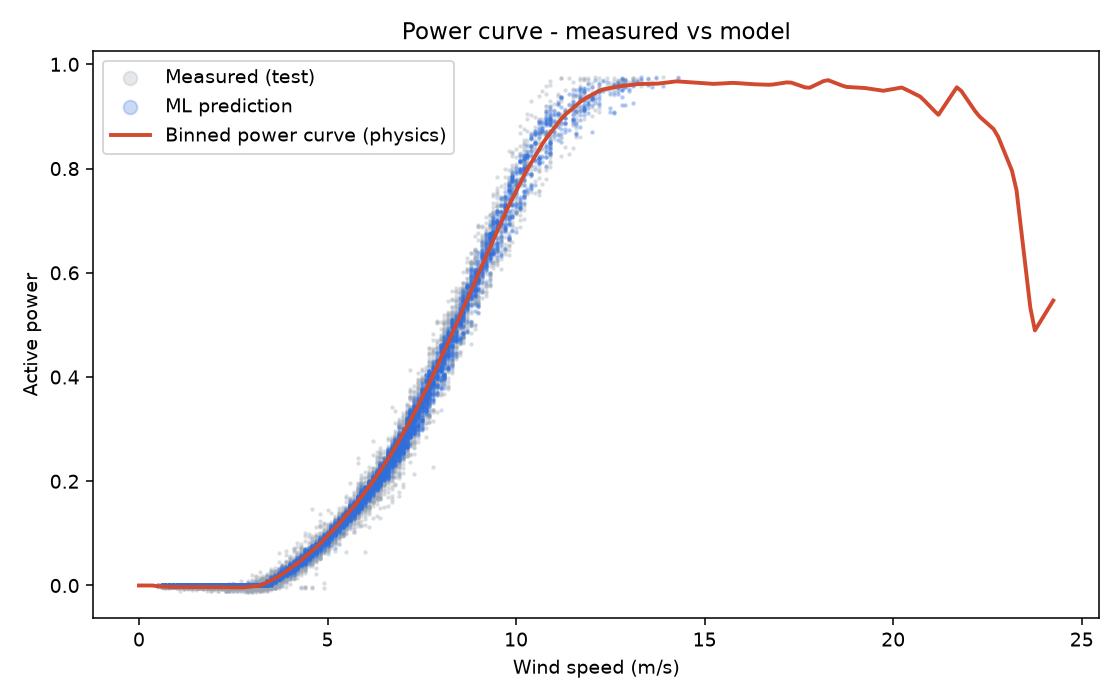

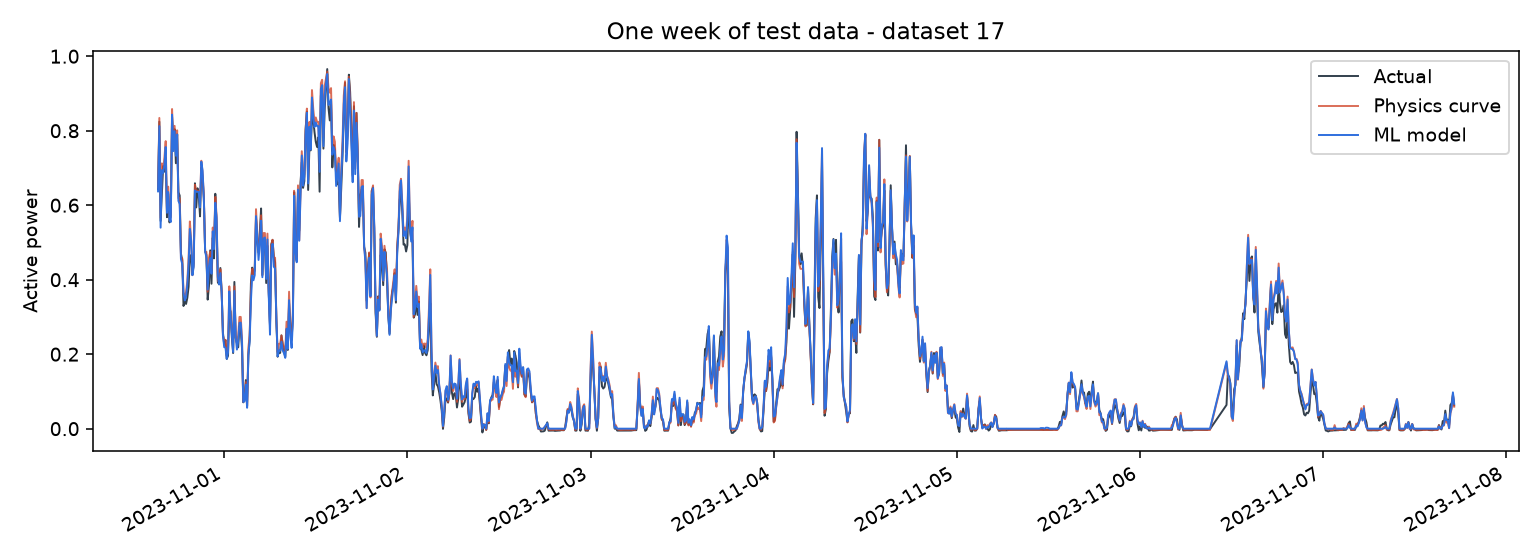

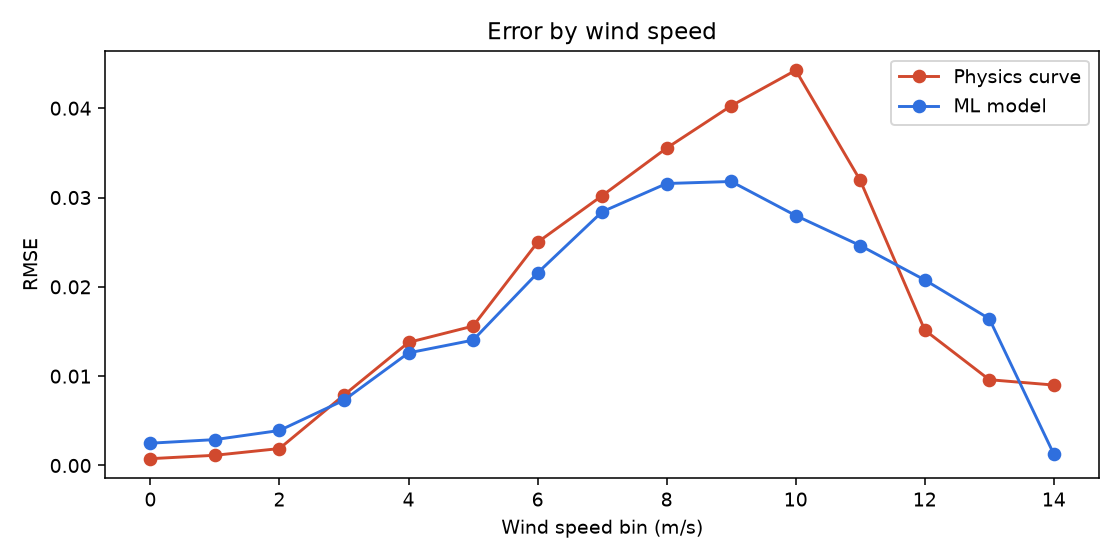

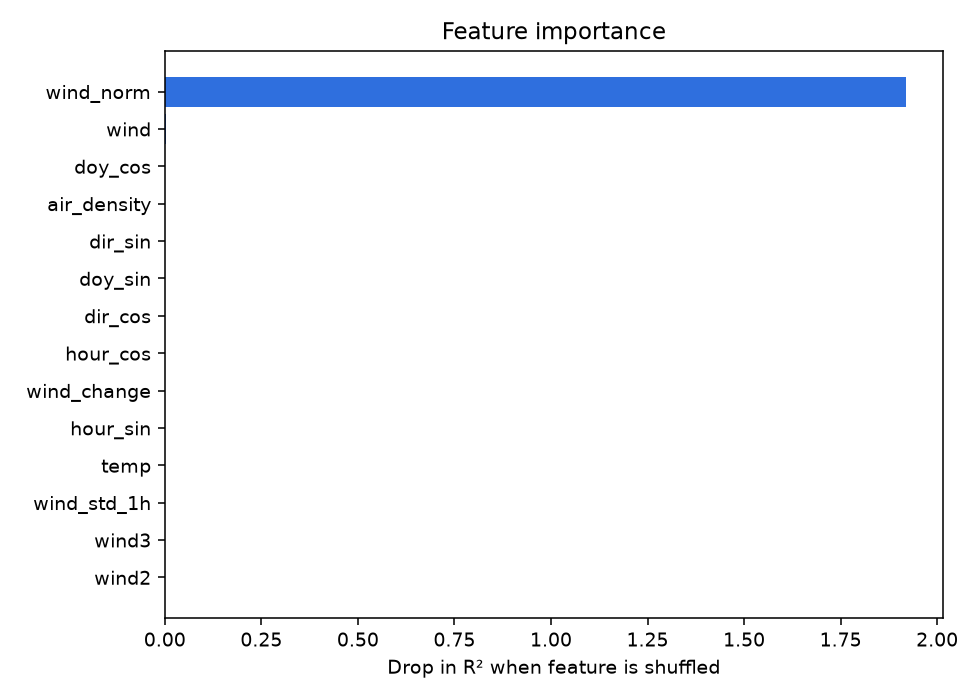

In [4]:
for f in ("power_curve.png", "timeseries_week.png", "error_by_windspeed.png", "feature_importance.png"):
    show(os.path.join(POWER_OUT, f))

## Step 2 - Fault detection
For each dataset: learn how every component normally behaves on the healthy period, then watch for
deviations in the prediction period (component temperatures, pitch, phase imbalance, power shortfall,
plus an autoencoder over all sensors). Alarm after a sustained deviation; the faulty component is named.

Settings below are the ones chosen by cross-validation (threshold 9, alarm after 3 h = 18 steps of 10 min).

In [5]:
RETRAIN_FAULT = False      # True = run again even if results exist (takes 15-20 min)
THRESHOLD     = 9          # alarm threshold (smoothed z-score)
ALARM_STEPS   = 18         # 18 x 10 min = 3 hours of sustained deviation

if RETRAIN_FAULT or not os.path.isfile(os.path.join(FAULT_OUT, "summary.json")):
    run_script("fault_detection.py", "--farm-dir", FARM_DIR,
               "--min-threshold", str(THRESHOLD), "--crit-limit", str(ALARM_STEPS))
else:
    print("Fault detection results already exist - skipping (set RETRAIN_FAULT = True to redo).")

Fault detection results already exist - skipping (set RETRAIN_FAULT = True to redo).


,Final run (chosen setting),Cross-validated (honest)
Faults detected,5/12,4/12
Normal turbines with a false alarm,0/10,0/10
Balanced accuracy,-,0.67
Warning before failure (median days),1.02,-
Correct component diagnosed,4/5,-


,dataset_id,asset,label,fault,detected,lead_time_days,diagnosed_subsystem,top_sensor,diagnosis_correct,false_alarm
0,0,0,anomaly,Generator bearing failure,False,NaN,NaN,NaN,NaN,False
1,3,10,normal,NaN,NaN,NaN,NaN,NaN,NaN,False
2,10,10,anomaly,Gearbox failure,True,5.99,Nacelle cabinets,NaN,False,False
3,13,21,normal,NaN,NaN,NaN,NaN,NaN,NaN,False
4,14,13,normal,NaN,NaN,NaN,NaN,NaN,NaN,False
5,17,10,normal,NaN,NaN,NaN,NaN,NaN,NaN,False
6,22,21,anomaly,Hydraulic group,True,0.04,Hub / pitch,NaN,True,False
7,24,0,normal,NaN,NaN,NaN,NaN,NaN,NaN,False
8,25,11,normal,NaN,NaN,NaN,NaN,NaN,NaN,False
9,26,0,anomaly,Hydraulic group,False,NaN,NaN,NaN,NaN,False


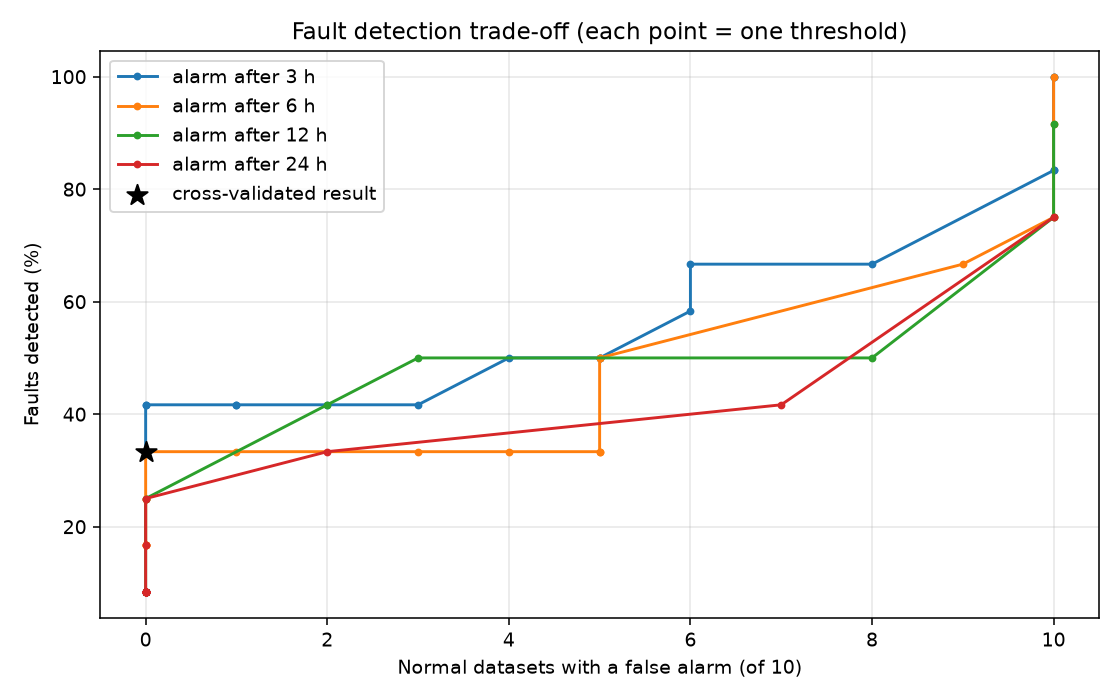

In [6]:
s  = json.load(open(os.path.join(FAULT_OUT, "summary.json")))
cvp = os.path.join(FAULT_OUT, "sweep_crossvalidation.json")
cv = json.load(open(cvp)) if os.path.isfile(cvp) else None

rows = {"Faults detected": (f"{s['detected']}/{s['anomaly_datasets']}",
                            f"{cv['detected']}/{cv['anomaly_datasets']}" if cv else "-"),
        "Normal turbines with a false alarm": (f"{s['normal_datasets_with_false_alarm']}/{s['normal_datasets']}",
                            f"{cv['normal_with_false_alarm']}/{cv['normal_datasets']}" if cv else "-"),
        "Balanced accuracy": ("-", f"{cv.get('balanced_accuracy', float('nan')):.2f}" if cv else "-"),
        "Warning before failure (median days)": (s.get("median_lead_time_days"), "-"),
        "Correct component diagnosed": (s.get("diagnosis_correct"), "-")}
display(pd.DataFrame(rows, index=["Final run (chosen setting)", "Cross-validated (honest)"]).T)

res = pd.read_csv(os.path.join(FAULT_OUT, "results_per_dataset.csv"))
cols = [c for c in ("dataset_id", "asset", "label", "fault", "detected", "lead_time_days",
                    "diagnosed_subsystem", "top_sensor", "diagnosis_correct", "false_alarm") if c in res]
display(res[cols])
show(os.path.join(FAULT_OUT, "sweep.png"))

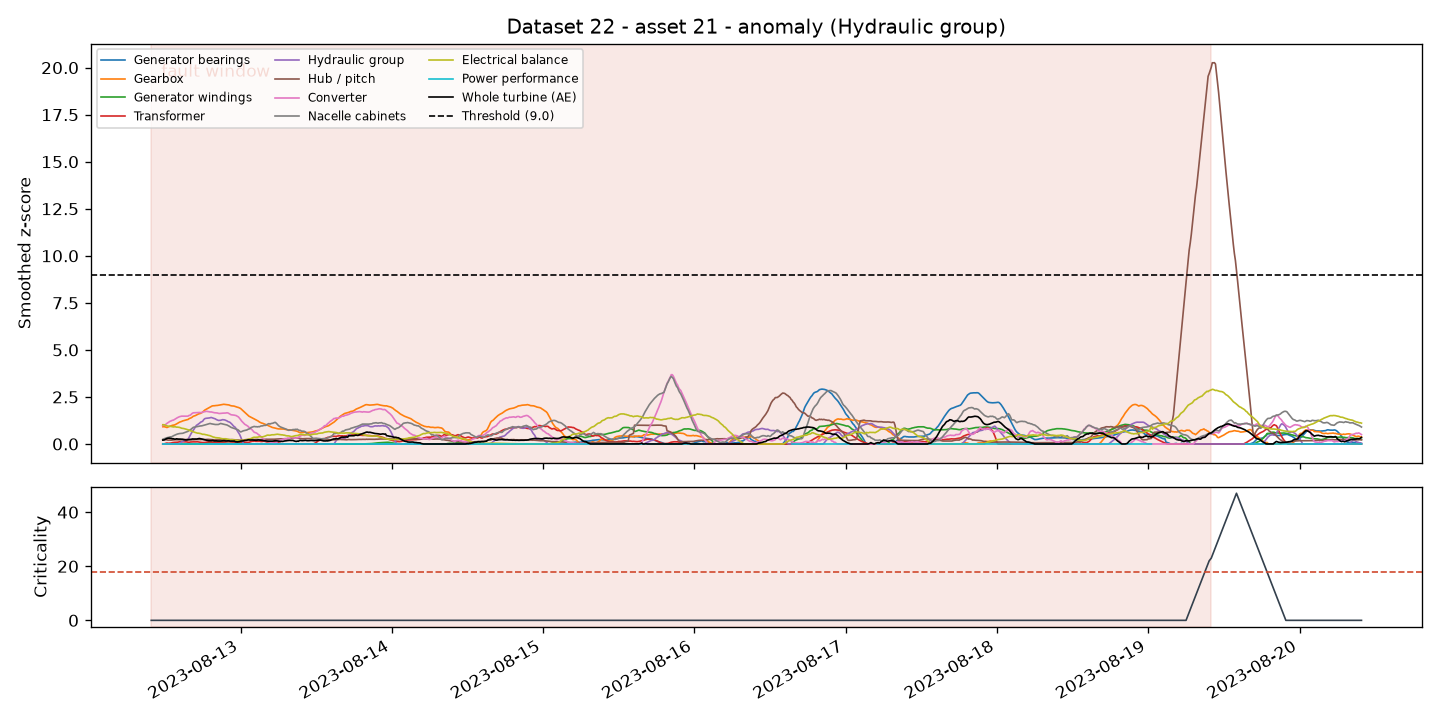

In [7]:
# Look at any dataset: change the number (anomaly examples: 22, 40, 42, 84; normal: 24, 69, 71)
DATASET = 22
show(os.path.join(FAULT_OUT, "plots", f"{DATASET}.png"), width=1000)

## Step 2b - Prediction of the future: power forecast (10 min to 3 h)
Gradient Boosting forecasts power 10 min, 1 h, 2 h and 3 h ahead from recent power and wind history,
with an 80 % range (10 % / 90 % quantile models). It is compared with *persistence* (\"power stays the same\");
skill > 0 means better than persistence. Takes a few minutes.

Forecast results already exist - skipping (set RETRAIN_FORECAST = True to redo).


,steps_ahead,nRMSE_%,nMAE_%,nRMSE_persistence_%,skill_vs_persistence,interval_coverage_80,test_rows
10 min,1.0,5.321,3.115,5.457,0.025,0.532,5370.0
1 h,6.0,11.028,6.993,11.759,0.062,0.531,5355.0
2 h,12.0,13.116,8.668,14.858,0.117,0.533,5338.0
3 h,18.0,14.919,9.886,17.197,0.132,0.532,5326.0


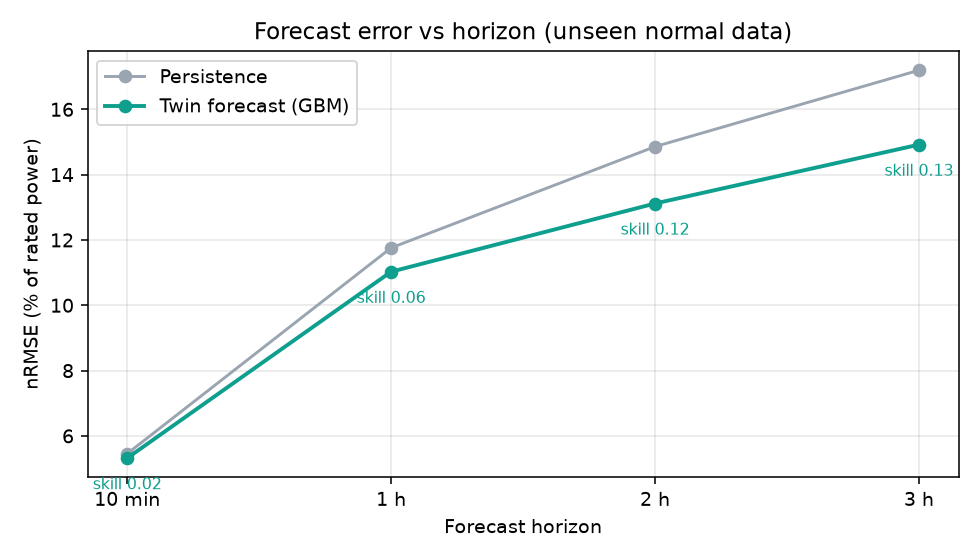

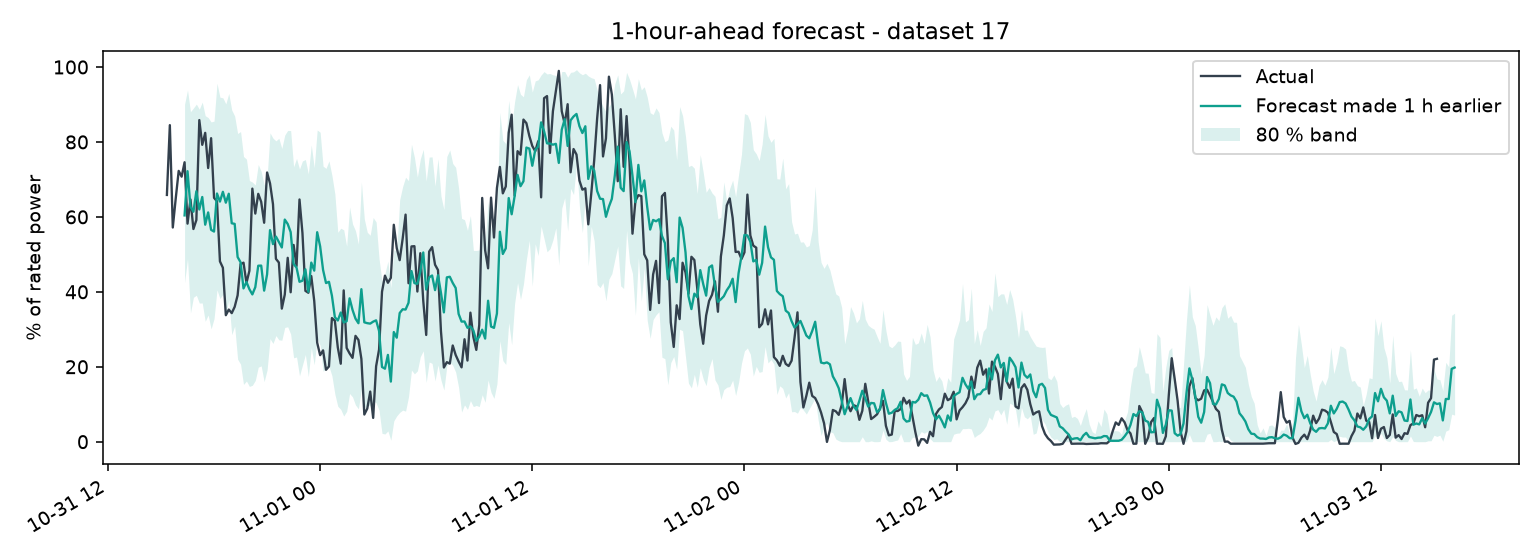

In [8]:
RETRAIN_FORECAST = False
if RETRAIN_FORECAST or not os.path.isfile(os.path.join(FORECAST_OUT, "metrics.json")):
    run_script("forecast_model.py", "--farm-dir", FARM_DIR)
else:
    print("Forecast results already exist - skipping (set RETRAIN_FORECAST = True to redo).")
fm = json.load(open(os.path.join(FORECAST_OUT, "metrics.json")))
display(pd.DataFrame(fm["horizons"]).T.round(3))
for f in ("forecast_skill.png", "forecast_example.png"):
    show(os.path.join(FORECAST_OUT, f))

## Step 2c - Health trend: time to alarm level
For every component, the slope of its health score over the last 24 h is projected forward to estimate
*when it would reach the alarm threshold*. This is an early-warning trend, **not** a true remaining useful life
(that would need run-to-failure data). Needs Step 2 results.

In [9]:
run_script("health_trend.py")
ht = json.load(open(os.path.join(FAULT_OUT, "health_trend_summary.json")))
display(pd.Series(ht, name="value").to_frame())

 dataset_id   label trend_warning_in_window alarm_in_window early_trend_warning_before_window    trend_subsystem false_trend_warning  hours_earlier_than_alarm
          0 anomaly                    True           False                             False        Hub / pitch                 NaN                       NaN
          3  normal                     NaN             NaN                               NaN                NaN                True                       NaN
         10 anomaly                    True            True                             False   Nacelle cabinets                 NaN                       5.7
         13  normal                     NaN             NaN                               NaN                NaN                True                       NaN
         14  normal                     NaN             NaN                               NaN                NaN               False                       NaN
         17  normal                     NaN   

,value
anomaly_datasets,12
normal_datasets,10
faults_with_trend_warning,5
faults_with_alarm,5
median_hours_trend_before_alarm,2.25
normal_datasets_with_trend_warning,5
settings,"{'scores': None, 'horizon_hours': 24, 'window_..."


## Step 3 - What-if: expected power for any weather
Uses the trained power model directly. Move the sliders (needs `ipywidgets`), or call `expected_power(...)` yourself.

In [10]:
import joblib

class BinnedPowerCurve:          # needed to load the saved physics power curve
    def predict(self, wind_norm):
        return np.interp(wind_norm, self.v_, self.p_, left=0.0, right=self.p_[-1])

import __main__
__main__.BinnedPowerCurve = BinnedPowerCurve   # the model was saved from a script's __main__
PM = joblib.load(os.path.join(POWER_OUT, "power_model.joblib"))

def expected_power(wind, temp_c=15, direction=270, gustiness=0.5, hour=14, month=6):
    """Expected power in % of rated, from the ML twin and from the physics power curve."""
    rho = 101325 / (287.05 * (temp_c + 273.15))
    doy = 30.4 * (month - 1) + 15
    f = {"wind": wind, "wind2": wind**2, "wind3": wind**3, "wind_norm": wind * (rho / 1.225) ** (1/3),
         "wind_std_1h": gustiness, "wind_change": 0.0, "air_density": rho,
         "hour_sin": np.sin(2*np.pi*hour/24), "hour_cos": np.cos(2*np.pi*hour/24),
         "doy_sin": np.sin(2*np.pi*doy/365.25), "doy_cos": np.cos(2*np.pi*doy/365.25),
         "temp": temp_c, "dir_sin": np.sin(np.deg2rad(direction)), "dir_cos": np.cos(np.deg2rad(direction))}
    X = pd.DataFrame([[f[c] for c in PM["features"]]], columns=PM["features"])
    ml = float(np.clip(PM["model"].predict(X)[0], 0, None)) / PM["rated_power"] * 100
    phys = float(PM["power_curve"].predict(np.array([f["wind_norm"]]))[0]) / PM["rated_power"] * 100
    return ml, phys, rho

def report(wind=8.0, temp_c=15.0, direction=270, gustiness=0.5, hour=14, month=6):
    ml, phys, rho = expected_power(wind, temp_c, direction, gustiness, hour, month)
    print(f"Wind {wind:.1f} m/s, {temp_c:.0f} °C (air density {rho:.3f} kg/m³)")
    print(f"  ML twin      : {ml:5.1f} % of rated power")
    print(f"  Power curve  : {phys:5.1f} % of rated power")

try:
    import ipywidgets as W
    W.interact(report,
               wind=W.FloatSlider(value=8, min=0, max=25, step=0.5, description="Wind m/s"),
               temp_c=W.FloatSlider(value=15, min=-10, max=40, step=1, description="Temp °C"),
               direction=W.IntSlider(value=270, min=0, max=359, step=5, description="Direction °"),
               gustiness=W.FloatSlider(value=0.5, min=0, max=3, step=0.1, description="Gustiness"),
               hour=W.IntSlider(value=14, min=0, max=23, description="Hour"),
               month=W.IntSlider(value=6, min=1, max=12, description="Month"))
except ImportError:
    print("ipywidgets not installed - showing examples instead:\n")
    for w in (4, 8, 12):
        report(w)

interactive(children=(FloatSlider(value=8.0, description='Wind m/s', max=25.0, step=0.5), FloatSlider(value=15…

## Step 4 - Digital twin dashboard
Starts the Streamlit app in the background and opens it in your browser (http://localhost:8501).
Keep this notebook open while you use it. Run the **stop** cell when you are done.

**Demo tip:** choose *Dataset 22 (hydraulic fault)*, tick *Show recorded fault window* and press **Play**.

In [13]:
dashboard = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", os.path.join(PROJECT_DIR, "digital_twin_app.py"),
     "--server.headless", "true", "--server.port", "8501"],
    cwd=PROJECT_DIR)
time.sleep(4)
if dashboard.poll() is None:
    print("Dashboard running at  http://localhost:8501")
    webbrowser.open("http://localhost:8501")
else:
    print("The dashboard did not start - run  streamlit run digital_twin_app.py  in a terminal to see why.")

Dashboard running at  http://localhost:8501


In [12]:
# Stop the dashboard
dashboard.terminate()
print("Dashboard stopped.")

Dashboard stopped.
